In [54]:
import numpy as np
import matplotlib.pyplot as plt
import pairinteraction as pi

Omega = 0.51  # MHz, Rabi frequency (paper's measured value)
distances = [0]  # µm

def compute_P2_and_B(Bfield_tesla, distances, Z):
    ket = pi.KetAtom("Rb", n=79, l=2, j=2.5, m=0.5)  # single-atom target state |r>
    basis = pi.BasisAtom("Rb", n=(74, 84), l=(0, 4))
    system = pi.SystemAtom(basis)
    system.set_magnetic_field([0, 0, Bfield_tesla], unit="tesla")

    system.diagonalize()                      # do this for B = 0 too
    overlaps = system.get_eigenbasis().get_overlaps(ket)
    idx = np.argmax(overlaps)
    E_r = system.get_eigenenergies(unit="MHz")[idx]
    pair_energy = 2 * E_r
    min_energy, max_energy = pair_energy - 500, pair_energy + 500

    pair_basis = pi.BasisPair(
        [system, system], energy=(min_energy, max_energy), energy_unit="MHz"
    )

    pair_systems = [
        pi.SystemPair(pair_basis).set_distance_vector([0, d, Z], unit="micrometer")
        for d in distances
    ]
    pi.diagonalize(pair_systems, diagonalizer="eigen")

    P2_vals = []
    B_vals = []
    for s in pair_systems:
        delta_phi = s.get_eigenenergies(unit="MHz") - pair_energy      # Delta_phi
        kappa2 = s.get_eigenbasis().get_overlaps([ket, ket])            # |<phi|rr>|^2

        P2 = np.sum(Omega**2 * kappa2 / (Omega**2 + 2 * delta_phi**2))
        P2 = min(P2, 1.0)  # guard against tiny numerical overshoot
        B = Omega * np.sqrt((1 - P2) / (2 * P2)) if P2 > 0 else np.inf

        P2_vals.append(P2)
        B_vals.append(B)

    return np.array(P2_vals), np.array(B_vals)

In [32]:
P2, B = compute_P2_and_B(1.15e-3, distances, 3.2)

<ErrorbarContainer object of 3 artists>

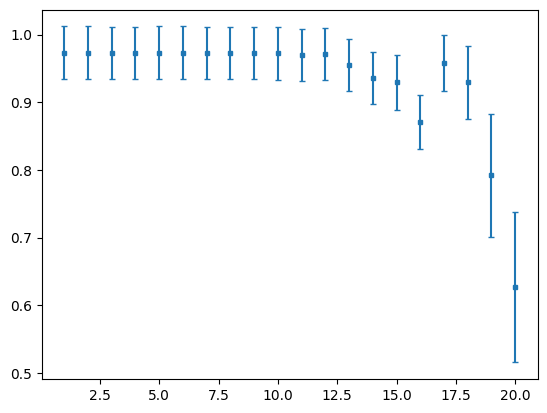

In [50]:
import numpy as np
from dataclasses import dataclass
from qutip import basis, qeye, tensor
from scipy.optimize import curve_fit

TWO_PI = 2 * np.pi
kB, amu = 1.380649e-23, 1.66053907e-27


@dataclass
class Params:
    # trap
    wf: float = 3.0            # trap waist (um)
    lam_f: float = 1.064       # trap wavelength (um)
    T: float = 180e-6          # atomic temperature (K)
    U0: float = 4.1e-3         # trap depth U0/kB (K)
    mass: float = 86.909 * amu # 87Rb
    # excitation beams (um)
    wx780: float = 11.9
    wz780: float = 7.0
    wx480: float = 11.3
    wz480: float = 9.0
    lam780: float = 0.780
    lam480: float = 0.480
    # laser / light-shift
    Omega0: float = TWO_PI * 0.51
    Delta0: float = 0.0
    b: float = 4.0
    # interaction, Gaussian fit of Delta_dd(yc - yt); n = 79 values
    Ddd0: float = TWO_PI * B[0]
    a_dd: float = TWO_PI * 0.11
    sig_dd: float = 4.3
    # SPAM parameters (set all to 1 for the ideal Fig. 5)
    eta_p: float = 1.0
    eta_Rd: float = 1.0


# ---------------------------------------------------------------- operators
g, r = basis(2, 0), basis(2, 1)
n = r * r.dag()
sx = g * r.dag() + r * g.dag()
I2 = qeye(2)
nc, nt = tensor(n, I2), tensor(I2, n)
sxc, sxt = tensor(sx, I2), tensor(I2, sx)


def H_pulse(Om_c, Om_t, D_c, D_t, Ddd):
    """Rotating-frame Hamiltonian (hbar = 1), real Rabi frequencies."""
    return (-D_c * nc - D_t * nt
            - 0.5 * Om_c * sxc - 0.5 * Om_t * sxt
            + Ddd * nc * nt)


# ---------------------------------------------------------- sampling pieces
class Sim:
    def __init__(self, p=Params(), seed=1):
        self.p = p
        self.rng = np.random.default_rng(seed)
        Trel = p.T / p.U0
        self.sig_xz = 0.5 * p.wf * np.sqrt(Trel)
        self.sig_y = np.pi * p.wf**2 / (np.sqrt(2) * p.lam_f) * np.sqrt(Trel)
        self.sig_v = np.sqrt(kB * p.T / p.mass)          # m/s == um/us
        self.dk = TWO_PI * (1 / p.lam780 - 1 / p.lam480)  # k1 - k2 (1/um)

    def envelope(self, x, y, z):
        """I(r)/I(0) = E780 * E480, Eq. (S2), exponent used exactly as written."""
        p, f = self.p, 1.0
        for wx, wz, lam in ((p.wx780, p.wz780, p.lam780),
                            (p.wx480, p.wz480, p.lam480)):
            Lx, Lz = np.pi * wx**2 / lam, np.pi * wz**2 / lam
            qx, qz = 1 + y**2 / Lx**2, 1 + y**2 / Lz**2
            f *= (qx * qz) ** -0.25 * np.exp(-x**2 / (wx**2 * qx)) \
                 * np.exp(-z**2 / (wz**2 * qz))
        return f

    def draw_atom(self):
        """Returns (Omega, Delta, y) for one atom in its own trap frame."""
        p, R = self.p, self.rng
        x, z = R.normal(0, self.sig_xz, 2)
        y = R.normal(0, self.sig_y)
        vy = R.normal(0, self.sig_v)
        Om = p.Omega0 * self.envelope(x, y, z)
        D = p.Delta0 + self.dk * vy + p.b * (Om - p.Omega0)
        return Om, D, y

    def Ddd(self, yc, yt):
        p = self.p
        return p.a_dd + (p.Ddd0 - p.a_dd) * np.exp(-(yc - yt)**2 / (2 * p.sig_dd**2))

    # ------------------------------------------------------- one realization
    def realization(self, t, with_control):
        p, R = self.p, self.rng
        Om_c, D_c, yc = self.draw_atom()
        Om_t, D_t, yt = self.draw_atom()
        t_pi = np.pi / p.Omega0

        if R.random() > p.eta_p:                 # target not optically pumped
            Pg = 1.0
        else:
            ctrl = with_control and (R.random() < p.eta_p)
            Ddd = self.Ddd(yc, yt) if ctrl else 0.0
            # D_c = 0 in the target pulse and D_t = 0 in the control pulse:
            # drops free-evolution phases, as the supplement does.
            Ut = (-1j * H_pulse(0, Om_t, 0, D_t, Ddd) * t).expm()
            if ctrl:
                Uc = (-1j * H_pulse(Om_c, 0, D_c, 0, Ddd) * t_pi).expm()
                M = Uc * Ut * Uc                  # Eq. (S1), right-to-left in time
            else:
                M = Ut
            Pg = abs(M[0, 0]) ** 2                # |a'_00|^2
        return Pg + (1 - p.eta_Rd) * (1 - Pg)     # photoionisation correction

    def curve(self, ts, with_control, N=100):
        mean, std = [], []
        for t in ts:
            s = np.array([self.realization(t, with_control) for _ in range(N)])
            mean.append(s.mean()); std.append(s.std(ddof=1))
        return np.array(mean), np.array(std)




import matplotlib.pyplot as plt

# ts = np.linspace(0, 4, 41)
eff = []
err = []
for Zed in np.linspace(1, 20, 20):
    P2, B = compute_P2_and_B(1.15e-3, distances, Zed)
    ts = [1]
    p = Params(Ddd0=TWO_PI*B[0], wf=1, T=60e-6, U0=1e-3)
    sim = Sim(p)
    free, e0 = sim.curve(ts, with_control=False)
    blk, e1 = sim.curve(ts, with_control=True)
    eff.append(blk[0])
    err.append(e1[0])

plt.errorbar(np.linspace(1, 20, 20), eff, yerr=err, fmt="s", ms=3, capsize=2)

<ErrorbarContainer object of 3 artists>

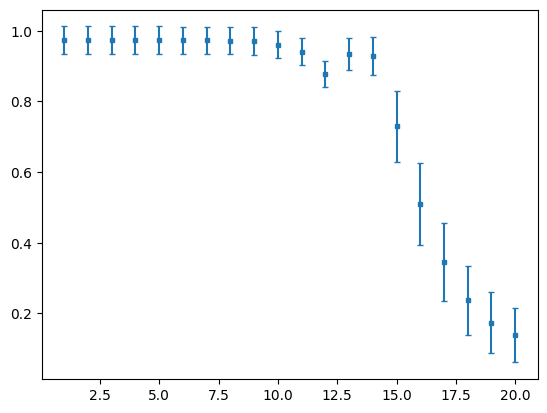

In [55]:
eff = []
err = []
for Zed in np.linspace(1, 20, 20):
    P2, B = compute_P2_and_B(1.15e-3, distances, Zed)
    ts = [1]
    p = Params(Ddd0=TWO_PI*B[0], wf=1, T=60e-6, U0=1e-3)
    sim = Sim(p)
    free, e0 = sim.curve(ts, with_control=False)
    blk, e1 = sim.curve(ts, with_control=True)
    eff.append(blk[0])
    err.append(e1[0])

plt.errorbar(np.linspace(1, 20, 20), eff, yerr=err, fmt="s", ms=3, capsize=2)